My goal in to compare data and word counts between the Iliad and the Odyessy to provide some evidence for (or against) the shared authorship of homer. To acheive this, I will either compare translated word counts or the original word counts. My hypothesis is that a given author prefers to use certain words more often than others and this will create something similar to a signature. If that signature can be compared to another work and matches, then there is a stronger likelihood that both works share an author.

<>:35: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:37: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:49: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:35: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:37: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:49: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\Ethan\AppData\Local\Temp\ipykernel_29956\2830821340.py:35: SyntaxWa

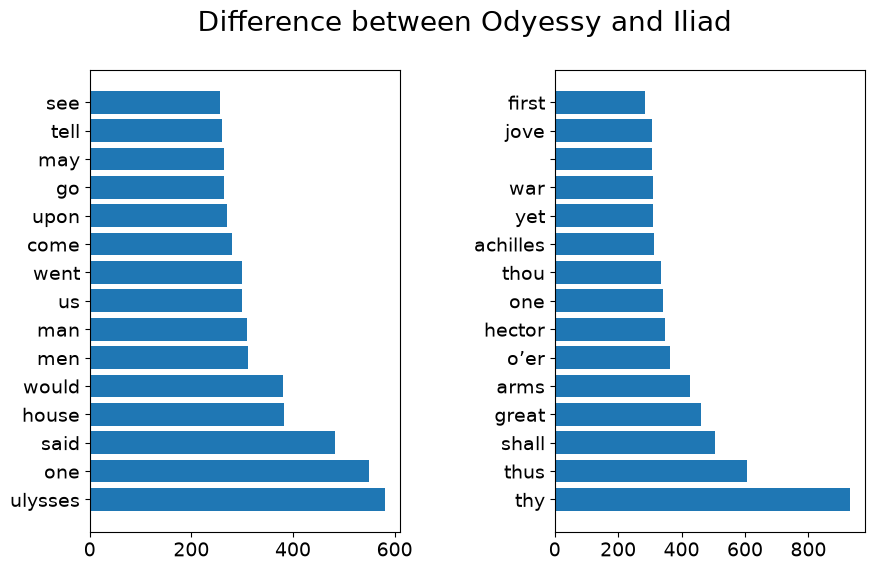

In [6]:
import requests, re
# re is a module for regular expressions: to detect various combinations of characters
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator
import numpy as np
import pylab
import matplotlib.pyplot as plt

# we may not care about the usage of stop words
try:
    stop_words = nltk.corpus.stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)
    stop_words = nltk.corpus.stopwords.words("english")

stop_words += [
    "ut", "'re", ".", ",", "--", "'s", "?", ")", "(", ":", "'",
    '"', "-", "}", "{", "&", "|", "\u2014"
]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
    
    # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs),15)

    #Reverse the list because barh plots items from the bottom
    return (wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists    
(wf_ee, tw_ee) = get_wf('http://www.gutenberg.org/ebooks/1727.txt.utf-8') # Odyessy
(wf_bu, tw_bu) = get_wf('http://www.gutenberg.org/ebooks/6130.txt.utf-8') # Iliad

%matplotlib inline
def plotTwoLists (wf_ee, wf_bu, title):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    plt .subplots_adjust (wspace=.5)

    pos = np .arange (len(wf_ee)+1) 
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_ee ])
    ax1 .barh (range(len(wf_ee)), [ x [1] for x in wf_ee ], align='center')

    ax2 = f .add_subplot (122)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
    pos = np .arange (len(wf_bu)+1) 
    pylab .yticks (pos, [ x [0] for x in wf_bu ])
    ax2 .barh (range (len(wf_bu)), [ x [1] for x in wf_bu ], align='center')

def plotTwoLists(wf_ee, wf_bu, title):
    fig = plt.figure(figsize=(10, 6))
    fig.suptitle(title, fontsize=20)

    ax1 = fig.add_subplot(121)
    ax2 = fig.add_subplot(122)
    plt.subplots_adjust(wspace=.5)

    for ax, wf in [(ax1, wf_ee), (ax2, wf_bu)]:
        y = np.arange(len(wf))
        labels = [x[0] for x in wf]
        values = [x[1] for x in wf]

        ax.tick_params(axis='both', which='major', labelsize=14)
        ax.barh(y, values, align='center')
        ax.set_yticks(y)
        ax.set_yticklabels(labels)
        ax.invert_yaxis()

    plt.show()

plotTwoLists(wf_ee, wf_bu, 'Difference between Odyessy and Iliad')